# Open Images: UMAP on DINOv2 image embeddings

Code for the [Open Images example](https://gprietos.github.io/posts/umap/#open-images-dataset) of the post [Dimensionality Reduction & Embedding Visualization — UMAP](https://gprietos.github.io/posts/umap/).

Pixels worked as features for [MNIST](mnist_umap.ipynb) because the digits are centered, all the same size and on a plain background. Real photos are different. Two photos of the same dog, taken from different angles, in different light or in other settings, can share almost no pixel values. So each image is first passed through an **embedding model**, which turns it into a vector where similar images are close, and UMAP lays out those vectors.

The model is **DINOv2** (ViT-B/14), a self-supervised vision model trained without labels. It was shown two different crops of the same image and asked to describe both in the same way. As a result, photos of similar things get similar embeddings, even when their framing, colors or lighting differ. Each image becomes a 768-D vector, and the vectors are compared with the cosine distance.

The data is a random sample of 25,000 images from the validation split of **Open Images V7**: everyday photos of all kinds of subjects, often with several objects in the same image. The notebook:
1. embeds the images and computes the 2-D UMAP map with k = 50;
2. shows the map without labels, then colored by Open Images' human-verified labels. The labels come from annotators, not from the model, so they are an independent check of what the embedding puts together;
3. compares it with UMAP's default k = 15.

**Warning:** the first run downloads the sample with the FiftyOne zoo into `data/zoo/open-images-v7/` (about 7 GB). Embedding takes a few minutes on a GPU and much longer on a CPU. Embeddings (field `emb_dinov2_vitb14`) and UMAP results (brain runs) are stored in the persistent FiftyOne dataset `open-images-v7-validation-25k`, so later runs only load them.

**License:** the Open Images annotations are CC BY 4.0, and the images are listed as CC BY 2.0 (attribution needed if you share them).

In [ ]:
import fiftyone as fo
import matplotlib.pyplot as plt

from umap_examples.embeddings import MODELS, embed
from umap_examples.openimages import group_labels, image_labels, load_dataset
from umap_examples.plotting import plot_maps, save_figure
from umap_examples.reduction import umap_run

## Config

In [ ]:
# Select 25k validation samples
SPLIT = "validation"
MAX_SAMPLES = 25000

# Embedding model
MODEL = "dinov2_vitb14"  # one of MODELS

# UMAP hyperparameters
N_NEIGHBORS = 50
MIN_DIST = 0.1

# Classes of the hierarchy: an image gets the first group it has a label under, the rest are "other".
GROUPS = ["Animal", "Food", "Vehicle", "Plant", "Building", "Person"]
IGNORE = {"Mammal"}
# Specific classes for a finer coloring, same rule (an Eagle counts as a Bird). Chosen because they are large and cluster well.
CLASSES = ["Dog", "Cat", "Bird", "Horse", "Car", "Airplane", "Boat", "Flower", "Baked goods"]

# Launch the FiftyOne App at the end?
INTERACTIVE = True       

print(list(MODELS))

## Dataset and embeddings

Downloaded once, then loaded. Only samples without an embedding are embedded.

In [ ]:
dataset = load_dataset(SPLIT, MAX_SAMPLES)
field = embed(dataset, MODEL)
dataset

Name:        open-images-v7-validation-25k
Media type:  image
Num samples: 25000
Persistent:  True
Tags:        []
Sample fields:
    id:                fiftyone.core.fields.ObjectIdField
    filepath:          fiftyone.core.fields.StringField
    tags:              fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:          fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:        fiftyone.core.fields.DateTimeField
    last_modified_at:  fiftyone.core.fields.DateTimeField
    positive_labels:   fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.Classifications)
    negative_labels:   fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.Classifications)
    emb_dinov2_vitb14: fiftyone.core.fields.VectorField
    group_label:       fiftyone.core.fields.StringField
    class_label:       fiftyone.core.fields.StringField

## UMAP

The 2-D map, stored as a brain run, so it also shows up in the FiftyOne App's Embeddings panel.

In [ ]:
points = umap_run(dataset, field, n_neighbors=N_NEIGHBORS, min_dist=MIN_DIST)
dataset.list_brain_runs()

['umap_emb_dinov2_vitb14_2d_k15_md00',
 'umap_emb_dinov2_vitb14_2d_k15_md01',
 'umap_emb_dinov2_vitb14_2d_k15_md05',
 'umap_emb_dinov2_vitb14_2d_k200_md00',
 'umap_emb_dinov2_vitb14_2d_k200_md01',
 'umap_emb_dinov2_vitb14_2d_k200_md05',
 'umap_emb_dinov2_vitb14_2d_k50_md00',
 'umap_emb_dinov2_vitb14_2d_k50_md01',
 'umap_emb_dinov2_vitb14_2d_k50_md05',
 'umap_emb_dinov2_vitb14_2d_k5_md00',
 'umap_emb_dinov2_vitb14_2d_k5_md01',
 'umap_emb_dinov2_vitb14_2d_k5_md05',
 'umap_emb_dinov2_vitb14_3d_k15_md01']

## Labels

Open Images organizes its 600 classes in a hierarchy, where specific classes such as Dog or Car belong to broader ones such as Animal or Vehicle. For the colors, each image gets one label: the first of the broad groups (Animal, Food, Vehicle, Plant, Building, Person) it has a class under (a dog counts as Animal), or "other". The same goes for the specific classes (Dog, Cat, Bird, Car, ...). Both are saved as fields to color by in the App.

In [ ]:
labels = image_labels(dataset)
groups = group_labels(labels, dataset.info["hierarchy"], GROUPS, ignore=IGNORE)
classes = group_labels(labels, dataset.info["hierarchy"], CLASSES)
dataset.set_values("group_label", groups)
dataset.set_values("class_label", classes)

## The map, without and with labels

The same map three times: alone, as you would get it on unlabeled data, then colored by broad groups of the class hierarchy, and by specific classes. Images without a label in any of these groups or classes are shown as "other". This is the figure in the post.

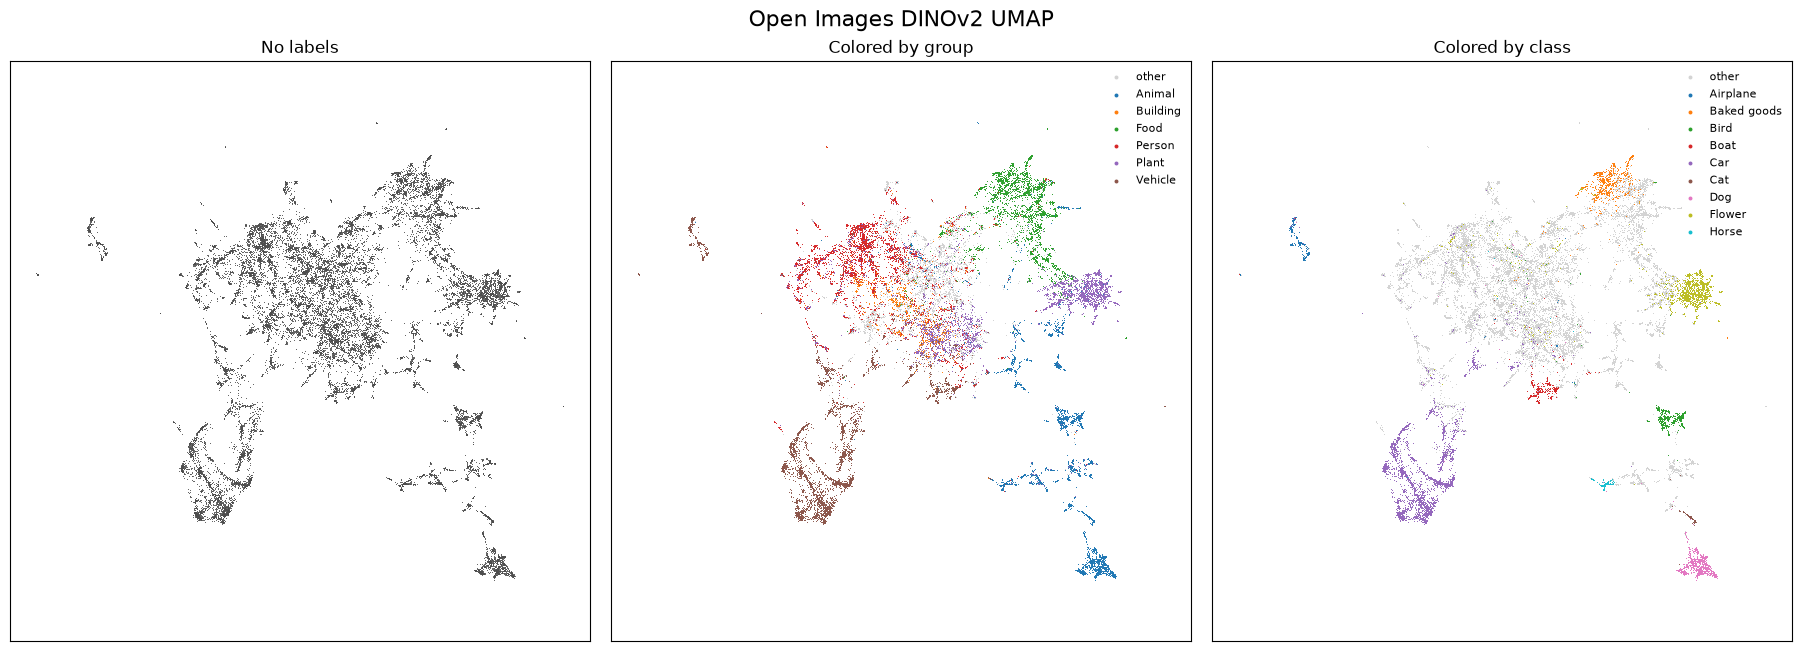

In [ ]:
maps = {"No labels": None, "Colored by group": groups, "Colored by class": classes}
fig = plot_maps(points, maps, title="Open Images DINOv2 UMAP")
save_figure(fig, f"openimages_{MODEL}_combined_k{N_NEIGHBORS}", dark=True)
plt.show()

Colored by broad group, vehicles, animals, food and plants each take up their own region. Colored by specific class, the regions split further. For example, dogs, cats, horses and birds form separate clusters within the animals, and cars, airplanes and boats within the vehicles.

The central region is different. Instead of separate clusters, it holds many related topics that blend into each other, such as people, clothing, buildings, landscapes, everyday objects and abstract concepts. Many photos there contain more than one of them, so the topics are linked through the images they share. People wear clothes, for example, so clothing almost merges with people. UMAP can't separate what the distances don't.

Note that the clusters come from DINOv2, not from UMAP. DINOv2's distances put these images together, and UMAP only represents the neighbor graph they define. Like any UMAP map, this one comes with the [weaknesses](https://gprietos.github.io/posts/umap/#umap-weaknesses) of the method, so splits, gaps and cluster sizes shouldn't be read as facts about the data. A different seed or other hyperparameters would give a different layout.

## Why k = 50?

With UMAP's default k = 15, each image is connected to only its 15 nearest neighbors. With 25,000 diverse images, the neighbor graph breaks into many small, weakly connected pieces, which show up as many small clusters whose relative positions mean nothing (check out [effect of k and min_dist](https://gprietos.github.io/posts/umap/#effect-of-k-and-min_dist-hyperparameters) in the post). A larger k connects more distant images, so the map keeps more of how the regions relate to each other.

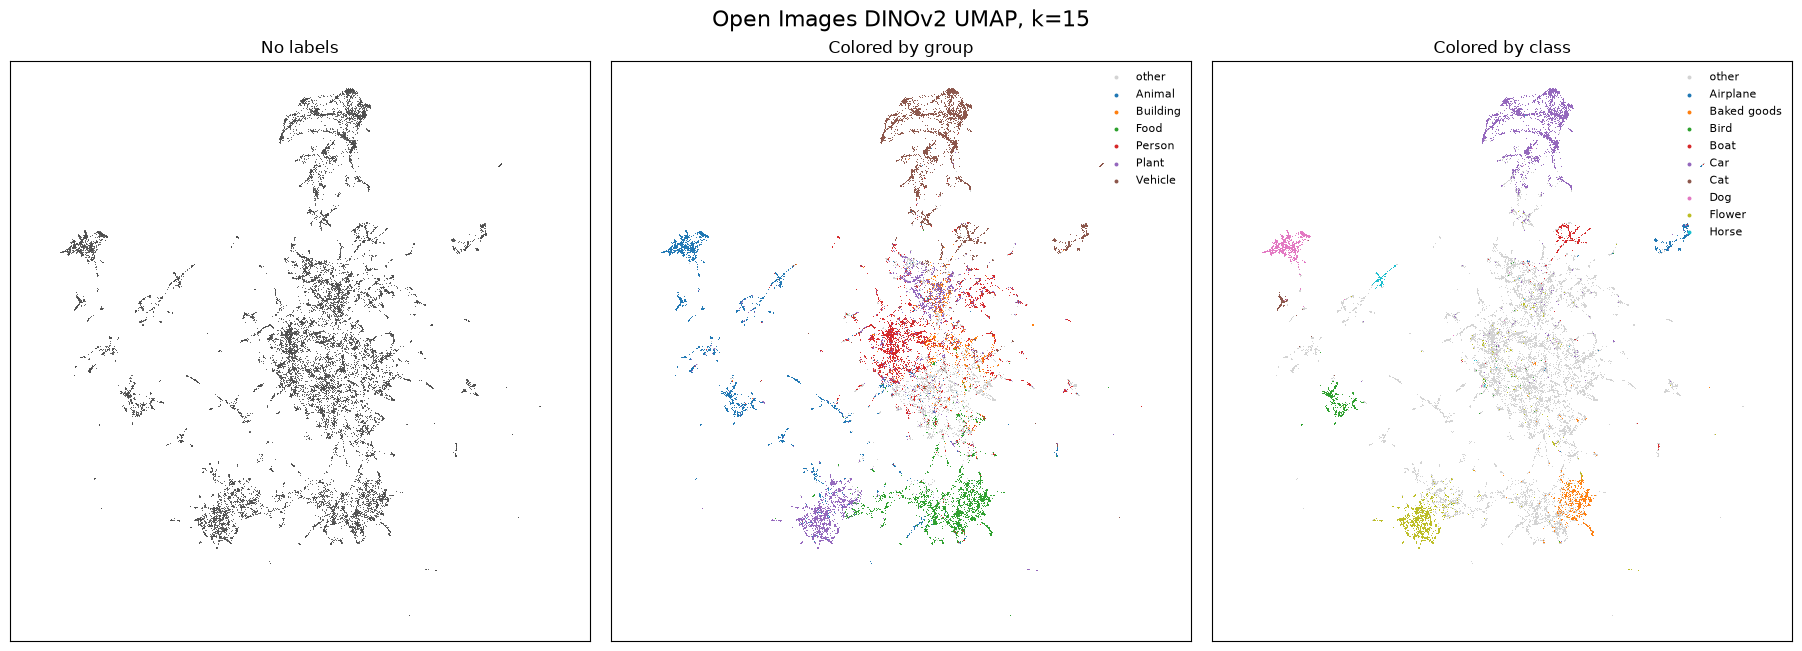

In [ ]:
points_k15 = umap_run(dataset, field, n_neighbors=15, min_dist=MIN_DIST)
fig = plot_maps(points_k15, maps, title="Open Images DINOv2 UMAP, k=15")
save_figure(fig, f"openimages_{MODEL}_combined_k15", dark=True)
plt.show()

## Browse in FiftyOne

To analyze the map further, the FiftyOne App shows the UMAP layout next to the images, as in the post's video. After running the cell below:

1. **Open the Embeddings panel:** click the **+** next to the **Samples** tab at the top and choose **Embeddings**.
2. **Pick a layout:** in the panel's first dropdown, choose the 2-D run of the post, `umap_emb_dinov2_vitb14_2d_k50_md01` (k = 50), or `umap_emb_dinov2_vitb14_2d_k15_md01` to compare with k = 15.
3. **Color the points:** in **Color by**, choose `group_label` for the broad groups or `class_label` for the specific classes.
4. **See the images:** lasso a region of the plot, and the grid shows only those images. Try the clusters around the edges, then the mixed central region.
5. **Show only one group or class:** in the sidebar on the left, open the dropdown menu that contains `group_label` or `class_label`, click the field and tick a value (for example Animal or Dog). Only those images remain, in the grid and in the plot.

In [ ]:
if INTERACTIVE:
    session = fo.launch_app(dataset)